# Stage C: Entity Resolution / Clustering

Merges MAC addresses that likely belong to the same physical hiker
(multi-device + mid-visit MAC rotation) into a single `Traveler_ID`, run
independently per sensor.

Design doc: `docs/specs/2026-07-29-stage-c-entity-resolution-design.md`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster

DATA_DIR = "../DATA"
BLOCK_GAP_THRESHOLD_S = 60  # same as Stage B's session gap threshold


## 1. Load Stage B sessions

In [2]:
sessions = {
    "A": pd.read_parquet(f"{DATA_DIR}/sessions_sensor_A.parquet").sort_values("start_time").reset_index(drop=True),
    "B": pd.read_parquet(f"{DATA_DIR}/sessions_sensor_B.parquet").sort_values("start_time").reset_index(drop=True),
}
for sensor, df in sessions.items():
    print(f"Sensor {sensor}: {len(df)} sessions")


Sensor A: 15267 sessions
Sensor B: 19359 sessions


## 2. Blocking

Purely a computational optimization: chain sessions into blocks so we only
compute pairwise comparisons within a block, not across the full 14-19K
sessions. Uses the same running-max-end-time + gap logic as Stage B's own
sessionization, with the same 60s gap allowance (covers a device rotating
its MAC mid-visit, since the old MAC's session can end right as the new
MAC's session starts a few seconds later).


In [3]:
def assign_blocks(df, gap_threshold_s=BLOCK_GAP_THRESHOLD_S):
    df = df.copy()
    running_max_end = df["end_time"].cummax()
    gap = (df["start_time"] - running_max_end.shift()).dt.total_seconds()
    new_block = gap.isna() | (gap > gap_threshold_s)
    df["block_id"] = new_block.cumsum()
    return df

for sensor in sessions:
    sessions[sensor] = assign_blocks(sessions[sensor])
    block_sizes = sessions[sensor]["block_id"].value_counts()
    print(f"Sensor {sensor}: {block_sizes.shape[0]} blocks, "
          f"max block size {block_sizes.max()}, median {block_sizes.median()}")


Sensor A: 410 blocks, max block size 745, median 7.0
Sensor B: 671 blocks, max block size 672, median 7.0


## 3. Candidate pairs within blocks

For every session pair within a block: `time_ok` if their intervals
overlap or the gap between them is <=60s, and a difference value
(`rssi_trend` difference in dBm/s, or `mean_rssi` difference in dB as a
fallback when either session has only 1 reading and no defined trend).


In [4]:
def compute_candidate_edges(df, gap_threshold_s=BLOCK_GAP_THRESHOLD_S):
    edge_frames = []
    for block_id, group in df.groupby("block_id"):
        n = len(group)
        if n < 2:
            continue
        starts = group["start_time"].to_numpy()
        ends = group["end_time"].to_numpy()
        trends = group["rssi_trend"].to_numpy()
        means = group["mean_rssi"].to_numpy()
        sess_ids = group["session_id"].to_numpy()

        i_idx, j_idx = np.triu_indices(n, k=1)
        s_i, s_j = starts[i_idx], starts[j_idx]
        e_i, e_j = ends[i_idx], ends[j_idx]

        overlap = np.minimum(e_i, e_j) - np.maximum(s_i, s_j)
        overlap_ok = overlap > np.timedelta64(0)
        gap_time = np.where(overlap_ok, np.timedelta64(0, "s"),
                             np.maximum(s_i, s_j) - np.minimum(e_i, e_j))
        gap_seconds = gap_time / np.timedelta64(1, "s")
        time_ok = overlap_ok | (gap_seconds <= gap_threshold_s)

        t_i, t_j = trends[i_idx], trends[j_idx]
        m_i, m_j = means[i_idx], means[j_idx]
        trend_diff = np.abs(t_i - t_j)
        mean_diff = np.abs(m_i - m_j)
        used_fallback = np.isnan(t_i) | np.isnan(t_j)
        diff_value = np.where(used_fallback, mean_diff, trend_diff)

        edge_frames.append(pd.DataFrame({
            "session_id_i": sess_ids[i_idx],
            "session_id_j": sess_ids[j_idx],
            "time_ok": time_ok,
            "diff_value": diff_value,
            "used_fallback": used_fallback,
        }))
    if not edge_frames:
        return pd.DataFrame(columns=["session_id_i", "session_id_j", "time_ok", "diff_value", "used_fallback"])
    return pd.concat(edge_frames, ignore_index=True)

candidate_edges = {}
for sensor, df in sessions.items():
    all_pairs = compute_candidate_edges(df)
    candidate_edges[sensor] = all_pairs[all_pairs["time_ok"]].reset_index(drop=True)
    print(f"Sensor {sensor}: {len(all_pairs)} pairs evaluated, "
          f"{len(candidate_edges[sensor])} pass the time_ok condition")


Sensor A: 1703201 pairs evaluated, 415517 pass the time_ok condition

Sensor B: 1722254 pairs evaluated, 533570 pass the time_ok condition


## 4. Threshold selection

There's no ground truth to tune against, so this is an inspected, documented
choice rather than a formula: we use the 10th percentile of the
candidate-pair difference distribution as a conservative cutoff (favoring
precision -- fewer, more confident merges -- over recall, since the busy
blocks found during design show hundreds of concurrent-but-unrelated
sessions that a loose threshold could wrongly merge together).


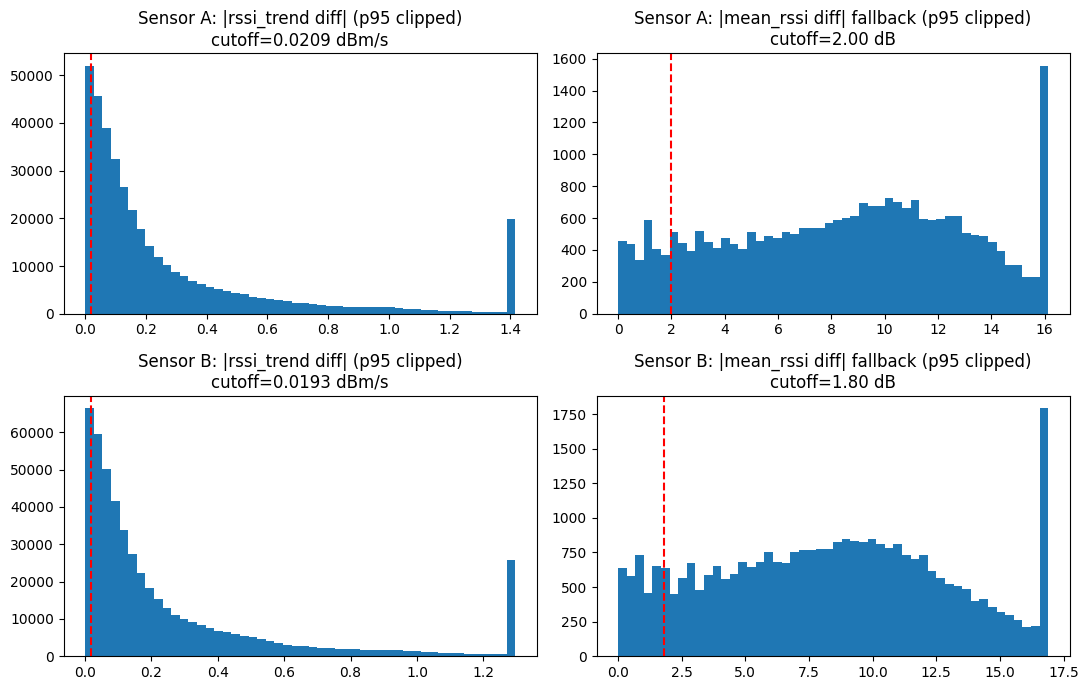

Sensor A: trend_diff cutoff = 0.0209 dBm/s, mean_rssi fallback cutoff = 2.00 dB
Sensor B: trend_diff cutoff = 0.0193 dBm/s, mean_rssi fallback cutoff = 1.80 dB


In [5]:
THRESHOLD_PERCENTILE = 10

thresholds = {}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, sensor in enumerate(["A", "B"]):
    edges = candidate_edges[sensor]
    trend_vals = edges.loc[~edges["used_fallback"], "diff_value"]
    fallback_vals = edges.loc[edges["used_fallback"], "diff_value"]

    trend_cutoff = np.percentile(trend_vals, THRESHOLD_PERCENTILE)
    fallback_cutoff = np.percentile(fallback_vals, THRESHOLD_PERCENTILE) if len(fallback_vals) else np.nan
    thresholds[sensor] = {"trend": trend_cutoff, "fallback": fallback_cutoff}

    axes[row, 0].hist(trend_vals.clip(upper=trend_vals.quantile(0.95)), bins=50)
    axes[row, 0].axvline(trend_cutoff, color="red", linestyle="--")
    axes[row, 0].set_title(f"Sensor {sensor}: |rssi_trend diff| (p95 clipped)\ncutoff={trend_cutoff:.4f} dBm/s")

    axes[row, 1].hist(fallback_vals.clip(upper=fallback_vals.quantile(0.95)), bins=50)
    axes[row, 1].axvline(fallback_cutoff, color="red", linestyle="--")
    axes[row, 1].set_title(f"Sensor {sensor}: |mean_rssi diff| fallback (p95 clipped)\ncutoff={fallback_cutoff:.2f} dB")

plt.tight_layout()
plt.show()

for sensor, t in thresholds.items():
    print(f"Sensor {sensor}: trend_diff cutoff = {t['trend']:.4f} dBm/s, "
          f"mean_rssi fallback cutoff = {t['fallback']:.2f} dB")


## 5. Merge -> Traveler_ID (complete-linkage clustering)

**First attempt used connected components (single-linkage), and it chained
badly**: testing found a 419-session component whose members' `rssi_trend`
ranged from -2.0 to +6.0 dBm/s, despite every individual pairwise edge
being under the 0.02 cutoff -- session 1 resembled session 2, which
resembled session 3, etc., but session 1 and session 419 were nothing
alike. Fixed by switching to **complete-linkage hierarchical clustering**
per block: this requires *every* pair within a merged group to be under
threshold, not just a chained path, which structurally rules out this
failure mode (complete linkage's merge height at each step equals the
resulting cluster's diameter, so cutting at a fixed threshold bounds the
diameter of every resulting cluster by that threshold).

Each pair's difference value is normalized by its own metric's threshold
(`trend_diff / trend_cutoff` or `mean_rssi_diff / fallback_cutoff`), so
both metrics share a common cutoff of `1.0`. Pairs that fail `time_ok` get
a large sentinel distance so they can never end up in the same cluster.


In [6]:
LARGE_SENTINEL = 1e6

def cluster_block(group, trend_cutoff, fallback_cutoff, gap_threshold_s=BLOCK_GAP_THRESHOLD_S):
    n = len(group)
    if n == 1:
        return np.array([1])

    starts = group["start_time"].to_numpy()
    ends = group["end_time"].to_numpy()
    trends = group["rssi_trend"].to_numpy()
    means = group["mean_rssi"].to_numpy()

    i_idx, j_idx = np.triu_indices(n, k=1)
    s_i, s_j = starts[i_idx], starts[j_idx]
    e_i, e_j = ends[i_idx], ends[j_idx]

    overlap = np.minimum(e_i, e_j) - np.maximum(s_i, s_j)
    overlap_ok = overlap > np.timedelta64(0)
    gap_time = np.where(overlap_ok, np.timedelta64(0, "s"),
                         np.maximum(s_i, s_j) - np.minimum(e_i, e_j))
    gap_seconds = gap_time / np.timedelta64(1, "s")
    time_ok = overlap_ok | (gap_seconds <= gap_threshold_s)

    t_i, t_j = trends[i_idx], trends[j_idx]
    m_i, m_j = means[i_idx], means[j_idx]
    trend_diff = np.abs(t_i - t_j)
    mean_diff = np.abs(m_i - m_j)
    used_fallback = np.isnan(t_i) | np.isnan(t_j)
    diff_value = np.where(used_fallback, mean_diff, trend_diff)
    cutoff = np.where(used_fallback, fallback_cutoff, trend_cutoff)

    normalized = diff_value / cutoff
    # condensed distance array, ordering matches np.triu_indices(n, k=1) / squareform convention
    condensed = np.where(time_ok, normalized, LARGE_SENTINEL)

    Z = linkage(condensed, method="complete")
    return fcluster(Z, t=1.0, criterion="distance")

for sensor, df in sessions.items():
    t = thresholds[sensor]
    traveler_id = pd.Series(index=df.index, dtype=object)
    for block_id, group in df.groupby("block_id"):
        labels = cluster_block(group, t["trend"], t["fallback"])
        traveler_id.loc[group.index] = [f"{sensor}-{block_id}-{label}" for label in labels]
    df["Traveler_ID"] = traveler_id

    n_travelers = df["Traveler_ID"].nunique()
    print(f"Sensor {sensor}: {len(df)} sessions -> {n_travelers} travelers")


Sensor A: 15267 sessions -> 7961 travelers


Sensor B: 19359 sessions -> 10516 travelers


## 6. Traveler summary table

In [7]:
traveler_summaries = {}

for sensor, df in sessions.items():
    summary = df.groupby("Traveler_ID").agg(
        sensor=("Traveler_ID", lambda s: sensor),
        n_devices=("MAC", "nunique"),
        MACs=("MAC", lambda s: sorted(set(s))),
        start_time=("start_time", "min"),
        end_time=("end_time", "max"),
        total_duration_s=("duration_s", "sum"),
    ).reset_index()
    traveler_summaries[sensor] = summary
    print(f"Sensor {sensor}: {len(summary)} travelers")

traveler_summaries["A"].sort_values("n_devices", ascending=False).head()


Sensor A: 7961 travelers


Sensor B: 10516 travelers


,Traveler_ID,sensor,n_devices,MACs,start_time,end_time,total_duration_s
2594,A-198-47,A,17,"[48:a9:1c:68:44:f0, 53:3f:78:3b:81:4e, 5b:d0:4...",2026-05-19 10:31:50,2026-05-19 10:42:23,3441.0
5553,A-329-121,A,16,"[04:19:f8:08:f9:69, 0e:79:9e:5f:50:3d, 23:56:a...",2026-05-25 11:03:56,2026-05-25 11:28:17,5679.0
2854,A-205-13,A,15,"[02:98:1f:6a:c3:6d, 11:fd:e8:db:5d:ca, 15:d5:0...",2026-05-19 12:18:16,2026-05-19 12:24:54,3013.0
1924,A-170-14,A,15,"[41:92:28:3a:cd:f3, 42:af:e0:ed:07:71, 4b:23:6...",2026-05-18 12:20:23,2026-05-18 12:23:53,1325.0
6398,A-385-71,A,14,"[28:8d:e9:3e:bb:3a, 3f:0b:5e:95:d6:c9, 52:71:f...",2026-05-28 10:26:00,2026-05-28 10:29:55,1086.0


## 7. Validation / sanity checks

In [8]:
for sensor, summary in traveler_summaries.items():
    dist = summary["n_devices"].value_counts().sort_index()
    print(f"Sensor {sensor}: n_devices distribution per traveler")
    print(dist)
    print()


Sensor A: n_devices distribution per traveler
n_devices
1     4502
2     1816
3      778
4      365
5      182
6      122
7       69
8       47
9       31
10      22
11       7
12      11
13       3
14       2
15       2
16       1
17       1
Name: count, dtype: int64

Sensor B: n_devices distribution per traveler
n_devices
1     6264
2     2316
3      913
4      437
5      227
6      132
7       76
8       48
9       35
10      27
11      15
12       7
13       6
14       2
15       1
16       4
17       1
18       2
19       1
20       1
22       1
Name: count, dtype: int64



In [9]:
for sensor, summary in traveler_summaries.items():
    n_sessions = len(sessions[sensor])
    n_travelers = len(summary)
    print(f"Sensor {sensor}: {n_sessions} sessions -> {n_travelers} travelers "
          f"({n_sessions - n_travelers} merges)")


Sensor A: 15267 sessions -> 7961 travelers (7306 merges)
Sensor B: 19359 sessions -> 10516 travelers (8843 merges)


In [10]:
# Flag the largest components as a sanity check -- an oversized component
# would indicate the threshold is too loose
for sensor, summary in traveler_summaries.items():
    largest = summary.sort_values("n_devices", ascending=False).head(5)
    print(f"Sensor {sensor}: largest travelers by device count")
    print(largest[["Traveler_ID", "n_devices", "start_time", "end_time", "total_duration_s"]])
    print()


Sensor A: largest travelers by device count
     Traveler_ID  n_devices          start_time            end_time  \
2594    A-198-47         17 2026-05-19 10:31:50 2026-05-19 10:42:23   
5553   A-329-121         16 2026-05-25 11:03:56 2026-05-25 11:28:17   
2854    A-205-13         15 2026-05-19 12:18:16 2026-05-19 12:24:54   
1924    A-170-14         15 2026-05-18 12:20:23 2026-05-18 12:23:53   
6398    A-385-71         14 2026-05-28 10:26:00 2026-05-28 10:29:55   

      total_duration_s  
2594            3441.0  
5553            5679.0  
2854            3013.0  
1924            1325.0  
6398            1086.0  

Sensor B: largest travelers by device count
     Traveler_ID  n_devices          start_time            end_time  \
9707    B-630-88         22 2026-05-30 13:25:21 2026-05-30 13:29:59   
9694    B-630-76         20 2026-05-30 13:23:16 2026-05-30 13:30:03   
4304    B-277-17         19 2026-05-19 10:32:00 2026-05-19 10:44:22   
3789    B-253-33         18 2026-05-18 12:27:17 20

In [11]:
# Spot-check: print the merged sessions for a couple of multi-device travelers
for sensor in ["A", "B"]:
    df = sessions[sensor]
    summary = traveler_summaries[sensor]
    multi = summary[summary["n_devices"] > 1].sort_values("n_devices", ascending=False)
    if len(multi) == 0:
        print(f"Sensor {sensor}: no multi-device travelers found")
        continue
    example_id = multi.iloc[len(multi) // 2]["Traveler_ID"]  # a mid-sized example, not the extreme
    print(f"Sensor {sensor}: Traveler_ID={example_id}")
    print(df[df["Traveler_ID"] == example_id][
        ["MAC", "start_time", "end_time", "duration_s", "n_readings", "mean_rssi", "rssi_trend"]
    ])
    print()


Sensor A: Traveler_ID=A-239-21
                    MAC          start_time            end_time  duration_s  \
9813  74:6e:97:47:f4:25 2026-05-20 12:04:06 2026-05-20 12:04:07         1.0   
9819  31:24:c4:f5:5c:93 2026-05-20 12:04:13 2026-05-20 12:04:13         0.0   

      n_readings  mean_rssi  rssi_trend  
9813           2      -93.0        -2.0  
9819           1      -93.0         NaN  

Sensor B: Traveler_ID=B-262-35
                    MAC          start_time            end_time  duration_s  \
8653  28:f1:b4:e3:3c:60 2026-05-18 14:52:29 2026-05-18 14:53:22        53.0   
8671  09:fc:af:a5:c2:ba 2026-05-18 14:53:34 2026-05-18 14:54:07        33.0   

      n_readings  mean_rssi  rssi_trend  
8653          49 -82.979592   -0.368822  
8671          32 -90.218750   -0.382450  



## 8. Travelers per day

Daily traveler counts, per sensor. A traveler's day is the calendar date of
their `start_time` (sessions never span midnight in this data -- all
observed activity falls within daytime hours -- so there's no ambiguity in
assigning a single day to a traveler).


In [12]:
daily_counts = {}
for sensor, summary in traveler_summaries.items():
    counts = (
        summary.assign(date=summary["start_time"].dt.date)
        .groupby("date")
        .size()
        .rename("n_travelers")
        .reset_index()
    )
    counts["sensor"] = sensor
    daily_counts[sensor] = counts
    print(f"Sensor {sensor}: travelers per day")
    print(counts[["date", "n_travelers"]].to_string(index=False))
    print()

travelers_per_day = pd.concat(daily_counts.values(), ignore_index=True)[["date", "sensor", "n_travelers"]]
travelers_per_day.head()


Sensor A: travelers per day
      date  n_travelers
2026-01-03          125
2026-02-26           66
2026-02-27          170
2026-02-28           10
2026-03-02            7
2026-03-03           10
2026-04-11           77
2026-05-02          220
2026-05-03          255
2026-05-09          322
2026-05-16         1410
2026-05-17          368
2026-05-18          902
2026-05-19          808
2026-05-20          380
2026-05-23         1167
2026-05-24          390
2026-05-25          683
2026-05-27          107
2026-05-28          444
2026-05-31           40

Sensor B: travelers per day
      date  n_travelers
2026-04-09           97
2026-04-10          219
2026-04-11          160
2026-05-02          114
2026-05-03          261
2026-05-04           16
2026-05-05          221
2026-05-06          778
2026-05-09          326
2026-05-16         1412
2026-05-17          387
2026-05-18          901
2026-05-19          834
2026-05-20          533
2026-05-21          499
2026-05-22           18
2026-05

,date,sensor,n_travelers
0,2026-01-03,A,125
1,2026-02-26,A,66
2,2026-02-27,A,170
3,2026-02-28,A,10
4,2026-03-02,A,7


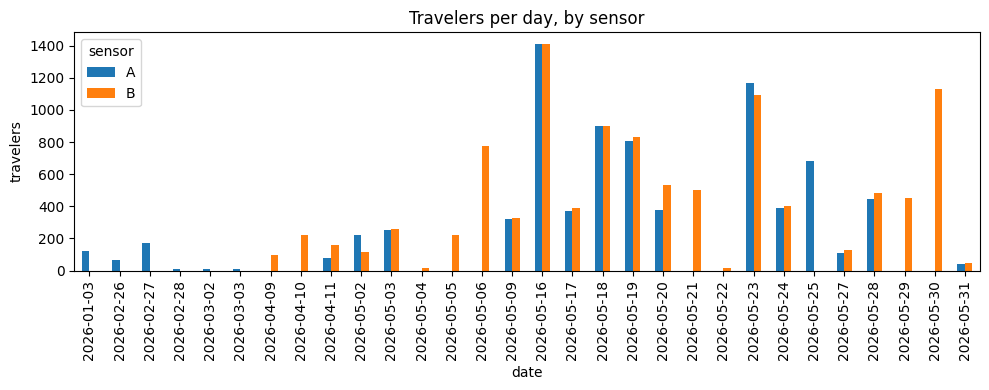

sensor,A,B
date,,
2026-01-03,125.0,0.0
2026-02-26,66.0,0.0
2026-02-27,170.0,0.0
2026-02-28,10.0,0.0
2026-03-02,7.0,0.0
2026-03-03,10.0,0.0
2026-04-09,0.0,97.0
2026-04-10,0.0,219.0
2026-04-11,77.0,160.0


In [13]:
pivot = travelers_per_day.pivot(index="date", columns="sensor", values="n_travelers").fillna(0)

fig, ax = plt.subplots(figsize=(10, 4))
pivot.plot(kind="bar", ax=ax)
ax.set_ylabel("travelers")
ax.set_title("Travelers per day, by sensor")
plt.tight_layout()
plt.show()

pivot


In [14]:
# Coverage check: days seen by only one sensor. On shared days the two
# sensors' counts track closely (e.g. 2026-05-18: 900 vs 901), which is a
# useful independent sanity check that the two per-sensor pipelines behave
# consistently -- but the collection days themselves don't fully overlap.
only_a = pivot[(pivot["A"] > 0) & (pivot["B"] == 0)]
only_b = pivot[(pivot["B"] > 0) & (pivot["A"] == 0)]
print(f"Days with Sensor A data only ({len(only_a)}): {list(only_a.index)}")
print(f"Days with Sensor B data only ({len(only_b)}): {list(only_b.index)}")


Days with Sensor A data only (7): [datetime.date(2026, 1, 3), datetime.date(2026, 2, 26), datetime.date(2026, 2, 27), datetime.date(2026, 2, 28), datetime.date(2026, 3, 2), datetime.date(2026, 3, 3), datetime.date(2026, 5, 25)]
Days with Sensor B data only (9): [datetime.date(2026, 4, 9), datetime.date(2026, 4, 10), datetime.date(2026, 5, 4), datetime.date(2026, 5, 5), datetime.date(2026, 5, 6), datetime.date(2026, 5, 21), datetime.date(2026, 5, 22), datetime.date(2026, 5, 29), datetime.date(2026, 5, 30)]


## 9. Save outputs

In [15]:
for sensor, df in sessions.items():
    out_cols = ["sensor", "MAC", "session_id", "start_time", "end_time",
                "duration_s", "n_readings", "mean_rssi", "rssi_trend", "Traveler_ID"]
    out = df[out_cols]
    out.to_csv(f"{DATA_DIR}/sessions_sensor_{sensor}_with_traveler.csv", index=False)
    out.to_parquet(f"{DATA_DIR}/sessions_sensor_{sensor}_with_traveler.parquet", index=False)

    summary = traveler_summaries[sensor]
    summary.to_csv(f"{DATA_DIR}/travelers_sensor_{sensor}.csv", index=False)
    summary.to_parquet(f"{DATA_DIR}/travelers_sensor_{sensor}.parquet", index=False)

    print(f"Sensor {sensor}: wrote {len(out)} sessions and {len(summary)} travelers")

travelers_per_day.to_csv(f"{DATA_DIR}/travelers_per_day.csv", index=False)
travelers_per_day.to_parquet(f"{DATA_DIR}/travelers_per_day.parquet", index=False)
print(f"wrote {len(travelers_per_day)} daily traveler-count rows")


Sensor A: wrote 15267 sessions and 7961 travelers


Sensor B: wrote 19359 sessions and 10516 travelers
wrote 44 daily traveler-count rows
